# Phase 1: Data exploration and baselines

**Goal:** understand where patient information (PHI) hides in the MIDI-B validation data,
and measure what standard de-identification gets. Every later phase must beat these numbers.

Parts:
1. Tag census: which tags exist (standard, private, inside sequences).
2. Where does PHI appear outside its "home" tag? (motivation for the PHI fingerprint)
3. Free text and burned-in text.
4. The answer key: which actions are required.
5. Three baselines, scored with the official MIDI-B script:
   - **B0 ids-only**: replace UIDs and Patient ID only (floor)
   - **BA basic**: DICOM PS3.15 Basic Profile
   - **BB basic+**: Basic Profile + Retain Dates (shifted) + Retain Patient Characteristics + Retain Device Identity
6. Error analysis of the best baseline.

In [1]:
import os
import glob
import shutil
import sqlite3
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pydicom

from fpdeid import paths
from fpdeid import census
from fpdeid import phi_locations
from fpdeid import baselines
from fpdeid import scoring
from fpdeid import validity

pd.set_option("display.max_colwidth", 80)
pd.set_option("display.width", 200)

phase_results = os.path.join(paths.RESULTS, "phase1")
os.makedirs(phase_results, exist_ok=True)

file_table_path = os.path.join(paths.DERIVED, "validation_file_table.csv")
file_table = pd.read_csv(file_table_path, dtype=str)
all_files = file_table["path"].tolist()
print("files:", len(all_files))

files: 23921


## 1. Tag census

We open every file (header only) and record every tag path, e.g. `(0008,1140)>(0008,1155)` for a tag inside a sequence.

In [2]:
start = time.time()
tag_census = census.build_census(all_files, workers=16)
print("seconds:", round(time.time() - start, 1))
print("distinct tag paths:", len(tag_census))

tag_census.to_csv(os.path.join(paths.DERIVED, "tag_census_with_examples.csv"), index=False)
no_examples = tag_census.drop(columns=["examples"])
no_examples.to_csv(os.path.join(phase_results, "tag_census.csv"), index=False)

seconds: 19.5
distinct tag paths: 1444


In [3]:
is_private = tag_census["private"] == True
is_nested = tag_census["depth"] > 0

census_summary = pd.Series({
    "distinct tag paths": len(tag_census),
    "standard, top level": int((~is_private & ~is_nested).sum()),
    "standard, inside sequences": int((~is_private & is_nested).sum()),
    "private, top level": int((is_private & ~is_nested).sum()),
    "private, inside sequences": int((is_private & is_nested).sum()),
})
census_summary

distinct tag paths            1444
standard, top level            439
standard, inside sequences     384
private, top level             602
private, inside sequences       19
dtype: int64

In [4]:
# which private creators are there (vendors)?
private_rows = tag_census[is_private].copy()
creator = private_rows["path"].str.extract(r'"([^"]+)"')[0]
private_rows["creator"] = creator
creator_counts = private_rows.groupby("creator")["path"].count().sort_values(ascending=False)
print("private creators:", len(creator_counts))
creator_counts.head(20)

private creators: 23


creator
GEMS_PETD_01                          178
GEMS_ACQU_01                          109
GEMS_PARM_01                           70
GEMS_IMAG_01                           30
UCSF BIRP PRIVATE CREATOR 011710XX     28
GEMS_HELIOS_01                         28
GEMS_RELA_01                           26
GEMS_SENO_02                           20
SIEMENS MR HEADER                      14
GEMS_SERS_01                            8
GEMS_IMPS_01                            7
GEMS_IDEN_01                            6
SIEMENS CT VA0  COAD                    5
EIGEN, INC                              4
GEMS_STDY_01                            3
PHILIPS PET PRIVATE GROUP               2
GEIIS PACS                              2
CTP                                     2
SIEMENS MEDCOM HEADER                   2
GEIIS                                   1
Name: path, dtype: int64

## 2. Where does PHI appear outside its home tag?

For each file we take its Patient Name (parts), Patient ID, Birth Date, Accession Number and Other Patient IDs,
and look for these values inside every *other* text tag of the same file.

In [5]:
start = time.time()
phi_hits = phi_locations.find_phi_outside_home(all_files, workers=16)
print("seconds:", round(time.time() - start, 1))

n_files = len(all_files)
n_files_with_hit = phi_hits["file"].nunique()
share = 100 * n_files_with_hit / n_files
print("files where PHI appears outside its home tag:", n_files_with_hit, "of", n_files, "=", round(share, 1), "%")

seconds: 8.4
files where PHI appears outside its home tag: 23641 of 23921 = 98.8 %


In [6]:
where = phi_hits.groupby(["home_tag", "found_in_name"]).agg(
    hits=("file", "count"),
    files=("file", "nunique"),
    private=("private", "max"),
)
where = where.sort_values("files", ascending=False).reset_index()
where.to_csv(os.path.join(phase_results, "phi_outside_home_tag.csv"), index=False)
where.head(25)

,home_tag,found_in_name,hits,files,private
0,PatientName,Series Description,18338,9236,False
1,PatientID,Series Description,7455,7455,False
2,PatientName,Additional Patient History,13963,7004,False
3,PatientID,Protocol Name,6975,6975,False
4,PatientName,Study Comments,11509,5815,False
5,PatientName,Requested Procedure Description,11310,5655,False
6,PatientName,Study Description,10336,5168,False
7,PatientName,Protocol Name,7828,3929,False
8,PatientName,Person Name,6792,3396,False
9,PatientID,Additional Patient History,2993,2993,False


In [7]:
# what would the Basic Profile do with these tags? (X = remove, K/not listed = keep, ...)
rules_basic = baselines.ps315.load_rules([])
rules_clean = baselines.ps315.load_rules(["clean_descriptors"])

keyword_to_action = {}
keyword_to_action_clean = {}
for tag_int in rules_basic:
    name = rules_basic[tag_int][2]
    keyword_to_action[name] = rules_basic[tag_int][0]
    keyword_to_action_clean[name] = rules_clean[tag_int][0]

where["basic_profile"] = where["found_in_name"].map(keyword_to_action).fillna("keep (not listed)")
where["with_clean_descriptors"] = where["found_in_name"].map(keyword_to_action_clean).fillna("keep (not listed)")
where.loc[where["private"] == True, "basic_profile"] = "X (private)"
where.head(25)

,home_tag,found_in_name,hits,files,private,basic_profile,with_clean_descriptors
0,PatientName,Series Description,18338,9236,False,X,C
1,PatientID,Series Description,7455,7455,False,X,C
2,PatientName,Additional Patient History,13963,7004,False,X,C
3,PatientID,Protocol Name,6975,6975,False,D,C
4,PatientName,Study Comments,11509,5815,False,X,C
5,PatientName,Requested Procedure Description,11310,5655,False,Z,C
6,PatientName,Study Description,10336,5168,False,X,C
7,PatientName,Protocol Name,7828,3929,False,D,C
8,PatientName,Person Name,6792,3396,False,D,D
9,PatientID,Additional Patient History,2993,2993,False,X,C


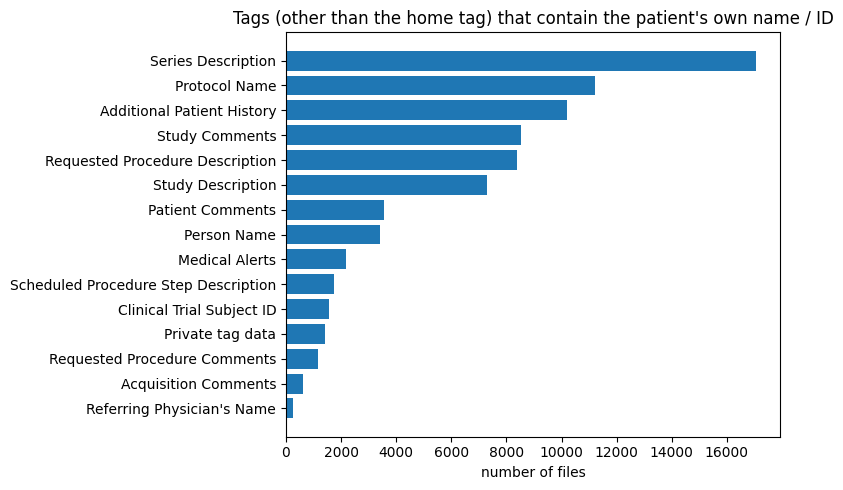

In [8]:
plot_data = phi_hits.groupby("found_in_name")["file"].nunique().sort_values().tail(15)
plt.figure(figsize=(8, 5))
plt.barh(plot_data.index, plot_data.values)
plt.xlabel("number of files")
plt.title("Tags (other than the home tag) that contain the patient's own name / ID")
plt.tight_layout()
plt.savefig(os.path.join(phase_results, "phi_outside_home_tag.png"), dpi=120)
plt.show()

## 3. Burned-in text (pixels)

In [9]:
burned = file_table.groupby("modality")["burned_in_annotation"].value_counts().unstack(fill_value=0)
burned

burned_in_annotation,NO
modality,
CR,23
CT,225
DX,34
MG,29
MR,452
US,143


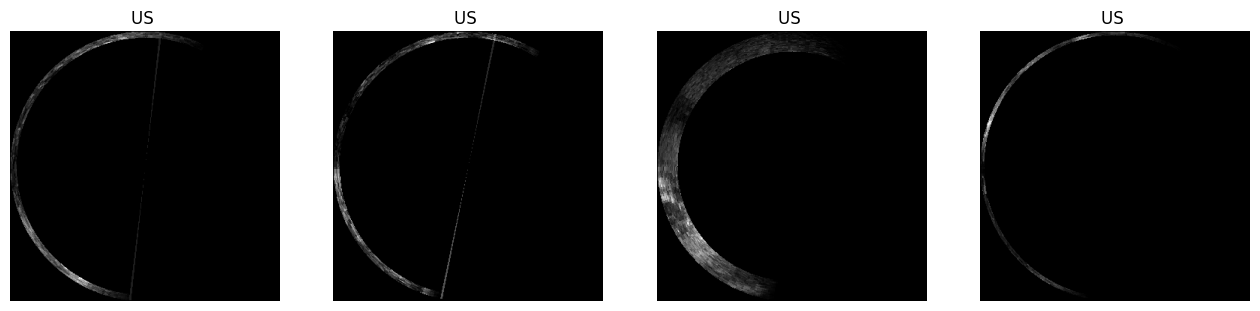

In [10]:
# show a few images from modalities that often have text in the pixels (US, SC, DX)
examples = file_table[file_table["modality"].isin(["US", "SC", "OT"])].head(4)
if len(examples) > 0:
    fig, axes = plt.subplots(1, len(examples), figsize=(4 * len(examples), 4))
    if len(examples) == 1:
        axes = [axes]
    for ax, path in zip(axes, examples["path"]):
        ds = pydicom.dcmread(path)
        image = ds.pixel_array
        if image.ndim == 4 or (image.ndim == 3 and image.shape[-1] != 3):
            image = image[0]
        ax.imshow(image, cmap="gray")
        ax.set_title(str(ds.Modality) + " " + str(ds.get("BurnedInAnnotation", "")))
        ax.axis("off")
    plt.show()

## 4. The answer key

Each answer-key row is one instance (or series/study/patient) with a JSON list of checks.
Check types: `<text_removed>`, `<text_retained>`, `<tag_retained>`, `<text_notnull>`, `<date_shifted>`,
`<uid_changed>`, `<uid_consistent>`, `<patid_consistent>`, `<pixels_hidden>`, `<pixels_retained>`.

In [11]:
answer_files = glob.glob(os.path.join(paths.VALIDATION_ANSWER_DIR, "**", "*.db"), recursive=True)
answer_db = answer_files[0]
print("answer key:", answer_db)

answer key: /home/ayra2/ayra_data/midi_b/validation/answer_key/MIDI-B-Answer-Key-Validation.db


In [12]:
# Open the JSON of every row into one long table of checks (one row per required check).
import json


def strip_brackets(text):
    if text is None:
        return ""
    return str(text).strip("<>")


check_rows = []
connection = sqlite3.connect(answer_db)
query = "SELECT Modality, SOPInstanceUID, AnswerData FROM answer_data"
n_answer_rows = 0
for chunk in pd.read_sql(query, connection, chunksize=2000):
    n_answer_rows = n_answer_rows + len(chunk)
    for _, row in chunk.iterrows():
        answer_dict = json.loads(row["AnswerData"])
        for key in answer_dict:
            check = answer_dict[key]
            check_rows.append({
                "modality": row["Modality"],
                "scope": strip_brackets(check.get("scope")),
                "action": strip_brackets(check.get("action")),
                "tag_name": strip_brackets(check.get("tag_name")),
                "tag": strip_brackets(check.get("tag")),
                "tag_ds": strip_brackets(check.get("tag_ds")),
            })
connection.close()

checks = pd.DataFrame(check_rows)
del check_rows
print("answer rows (instances):", n_answer_rows)
print("required checks:", len(checks))

action_counts = checks["action"].value_counts()
action_counts.to_csv(os.path.join(phase_results, "answer_key_actions.csv"))
action_counts

answer rows (instances): 23921
required checks: 6173204


action
text_retained       3453539
tag_retained        1101091
text_notnull         618539
text_removed         343583
uid_changed          234418
uid_consistent       234418
date_shifted         139774
patid_consistent      23921
pixels_retained       23886
pixels_hidden            35
Name: count, dtype: int64

In [13]:
top_tags = checks.groupby(["action", "tag_name"]).size().sort_values(ascending=False)
top_tags = top_tags.reset_index(name="checks")
top_tags.to_csv(os.path.join(phase_results, "answer_key_top_tags.csv"), index=False)
top_tags.head(30)

,action,tag_name,checks
0,text_retained,Coding Scheme Designator,108285
1,text_retained,Code Meaning,107645
2,text_retained,Code Value,102766
3,text_retained,Private Creator,79548
4,text_retained,[PET compatible_version],34128
5,text_removed,Accession Number,31569
6,uid_consistent,Series Instance UID,30151
7,uid_changed,Series Instance UID,30151
8,uid_changed,Study Instance UID,30141
9,uid_consistent,Study Instance UID,30141


In [14]:
# Pass criterion: every tag path that the answer key checks must appear in our tag census.
import re


def key_path_to_census_path(key_path):
    path = re.sub(r">?\[<\d+>\]<?", ">", key_path)
    path = path.replace("<", "").replace(">>", ">")
    return path.upper()


key_paths = set()
for tag_ds in checks["tag_ds"].unique():
    if tag_ds != "":
        key_paths.add(key_path_to_census_path(tag_ds))

census_tags = set(tag_census["path"].str.upper())
found = key_paths & census_tags
coverage = 100 * len(found) / len(key_paths)
print("tag paths in answer key:", len(key_paths))
print("found in our census    :", len(found), "(", round(coverage, 2), "% )")
not_found = sorted(key_paths - census_tags)
print("not found:", len(not_found))
for path in not_found[:10]:
    print("  ", path)

tag paths in answer key: 1294
found in our census    : 1277 ( 98.69 % )
not found: 17
   (0008,0001)
   (0117,"UCSF BIRP PRIVATE CREATOR 011710XX",20)>(0117,"UCSF BIRP PRIVATE CREATOR 011710XX",41)
   (0117,"UCSF BIRP PRIVATE CREATOR 011710XX",20)>(0117,"UCSF BIRP PRIVATE CREATOR 011710XX",42)
   (0117,"UCSF BIRP PRIVATE CREATOR 011710XX",20)>(0117,"UCSF BIRP PRIVATE CREATOR 011710XX",43)
   (0117,"UCSF BIRP PRIVATE CREATOR 011710XX",20)>(0117,"UCSF BIRP PRIVATE CREATOR 011710XX",44)
   (0117,"UCSF BIRP PRIVATE CREATOR 011710XX",20)>(0117,"UCSF BIRP PRIVATE CREATOR 011710XX",45)
   (0117,"UCSF BIRP PRIVATE CREATOR 011710XX",20)>(0117,"UCSF BIRP PRIVATE CREATOR 011710XX",46)
   (0117,"UCSF BIRP PRIVATE CREATOR 011710XX",24)>(0117,"UCSF BIRP PRIVATE CREATOR 011710XX",C0)
   (0117,"UCSF BIRP PRIVATE CREATOR 011710XX",24)>(0117,"UCSF BIRP PRIVATE CREATOR 011710XX",C1)
   (0117,"UCSF BIRP PRIVATE CREATOR 011710XX",24)>(0117,"UCSF BIRP PRIVATE CREATOR 011710XX",C2)


In [15]:
# required checks per modality and action
by_modality = pd.crosstab(checks["modality"], checks["action"], margins=True)
by_modality.to_csv(os.path.join(phase_results, "answer_key_by_modality.csv"))
by_modality

action,date_shifted,patid_consistent,pixels_hidden,pixels_retained,tag_retained,text_notnull,text_removed,text_retained,uid_changed,uid_consistent,All
modality,,,,,,,,,,,
CR,162,26,14,12,702,338,190,1521,90,90,3145
CT,19776,4406,0,4406,157626,87580,57316,341250,20910,20910,714180
DX,223,34,18,16,1330,850,227,2539,150,150,5537
MG,90,31,3,28,1316,929,225,11212,121,121,14076
MR,17682,3511,0,3511,133418,70220,61271,510836,16204,16204,832857
PT,100916,15724,0,15724,801924,455996,222276,2534004,191480,191480,4529524
SR,138,22,0,22,528,264,279,44097,4938,4938,55226
US,787,167,0,167,4247,2362,1799,8080,525,525,18659
All,139774,23921,35,23886,1101091,618539,343583,3453539,234418,234418,6173204


In [16]:
# the burned-in text checks (pixels_hidden) — how many and in which modalities?
pixel_checks = checks[checks["action"] == "pixels_hidden"]
print("pixels_hidden checks:", len(pixel_checks))
pixel_checks["modality"].value_counts()

pixels_hidden checks: 35


modality
DX    18
CR    14
MG     3
Name: count, dtype: int64

## 5. Baselines

For each baseline: de-identify all files -> score with the official script -> check validity on a sample
-> delete the output files (to save disk), keep only the scores.

In [17]:
mappings = baselines.Mappings(paths.VALIDATION_UID_MAP, paths.VALIDATION_PATIENT_MAP)

scorer_out = os.path.join(paths.DERIVED, "scorer_runs")
os.makedirs(scorer_out, exist_ok=True)

all_results = {}
all_summaries = {}

rng = np.random.default_rng(0)
validity_sample_size = 1000

for name in ["B0", "BA", "BB"]:
    print("=====", name, "=====")

    saved_db = os.path.join(scorer_out, "phase1_" + name, "validation_results.db")
    saved_summary = os.path.join(paths.DERIVED, "summary_" + name + ".csv")
    if os.path.exists(saved_db) and os.path.exists(saved_summary):
        results = scoring.add_categories(scoring.load_results(saved_db))
        all_results[name] = results
        all_summaries[name] = pd.read_csv(saved_summary, index_col=0).iloc[:, 0].to_dict()
        print("reused saved results")
        continue

    out_folder = os.path.join(paths.OUTPUTS, "phase1_" + name)
    shutil.rmtree(out_folder, ignore_errors=True)

    start = time.time()
    run_table = baselines.run_baseline(all_files, out_folder, name, mappings, workers=16)
    deid_seconds = time.time() - start
    n_errors = (run_table["error"] != "").sum()
    print("de-identified in", round(deid_seconds), "s, errors:", n_errors)

    start = time.time()
    db_path = scoring.run_official_scorer("phase1_" + name, out_folder, answer_db,
                                          paths.VALIDATION_UID_MAP, paths.VALIDATION_PATIENT_MAP,
                                          scorer_out, cpus=16)
    print("scored in", round(time.time() - start), "s")
    results = scoring.load_results(db_path)
    results = scoring.add_categories(results)
    all_results[name] = results

    ok_rows = run_table[run_table["error"] == ""]
    sample_index = rng.choice(len(ok_rows), size=min(validity_sample_size, len(ok_rows)), replace=False)
    sample = ok_rows.iloc[sample_index]
    pairs = list(zip(sample["input"], sample["output"]))
    valid_table = validity.check_pairs(pairs, workers=16)
    valid_pct = 100 * (valid_table["new_errors"] == 0).mean()

    summary = scoring.summarise(results)
    summary.update(scoring.privacy_utility(results))
    summary["valid_files_%_sample"] = round(valid_pct, 2)
    summary["deid_errors"] = int(n_errors)
    summary["files_per_second"] = round(len(all_files) / deid_seconds, 1)
    all_summaries[name] = summary
    pd.Series(summary).to_csv(saved_summary)
    valid_table.to_csv(os.path.join(paths.DERIVED, "validity_" + name + ".csv"), index=False)

    shutil.rmtree(out_folder, ignore_errors=True)
    print(pd.Series(summary))

===== B0 =====


reused saved results
===== BA =====


reused saved results
===== BB =====


reused saved results


In [18]:
baseline_table = pd.DataFrame(all_summaries)
baseline_table.to_csv(os.path.join(phase_results, "baseline_scores.csv"))
baseline_table

,B0,BA,BB
checks,6173204.000,6173204.000,6173204.000
plain_accuracy_%,91.743,72.594,75.875
hipaa_checks,567859.000,567859.000,567859.000
hipaa_accuracy_%,45.832,99.989,99.988
dicom_checks,1977969.000,1977969.000,1977969.000
dicom_accuracy_%,99.889,99.885,99.885
tcia_checks,3627376.000,3627376.000,3627376.000
tcia_accuracy_%,94.489,53.424,59.007
weighted_score_%,61.509,95.311,95.870
privacy_checks,717810.000,717810.000,717810.000


### Accuracy per action type

In [19]:
per_action_tables = []
for name in all_results:
    table = scoring.per_action(all_results[name])
    table = table[["checks", "accuracy_%"]].rename(columns={"accuracy_%": name})
    per_action_tables.append(table[[name]])
per_action_all = pd.concat(per_action_tables, axis=1)
per_action_all.insert(0, "checks", scoring.per_action(all_results["BA"])["checks"])
per_action_all.to_csv(os.path.join(phase_results, "baseline_per_action.csv"))
per_action_all

,checks,B0,BA,BB
action,,,,
<date_shifted>,139774,0.000,100.000,100.000
<patid_consistent>,23921,100.000,100.000,100.000
<pixels_hidden>,35,17.143,17.143,17.143
<pixels_retained>,23886,100.000,100.000,100.000
<tag_retained>,1101091,99.806,99.801,99.801
<text_notnull>,618539,99.991,99.991,99.991
<text_removed>,343583,8.459,93.801,90.957
<text_retained>,3453539,98.460,51.696,57.844
<uid_changed>,234418,100.000,99.986,99.986


### Accuracy per modality

In [20]:
modality_tables = []
for name in all_results:
    table = all_results[name].copy()
    table["passed"] = table["check_passed"].fillna(0).astype(float)
    accuracy = table.groupby("modality")["passed"].mean() * 100
    modality_tables.append(accuracy.round(2).rename(name))
per_modality = pd.concat(modality_tables, axis=1)
per_modality.to_csv(os.path.join(phase_results, "baseline_per_modality.csv"))
per_modality

,B0,BA,BB
modality,,,
<CR>,89.28,91.51,96.72
<CT>,89.64,79.37,83.00
<DX>,90.07,88.89,93.48
<MG>,97.96,98.64,99.40
<MR>,89.81,65.70,68.72
<PT>,92.34,72.31,75.60
<SR>,99.28,98.04,99.68
<US>,87.04,86.67,93.33


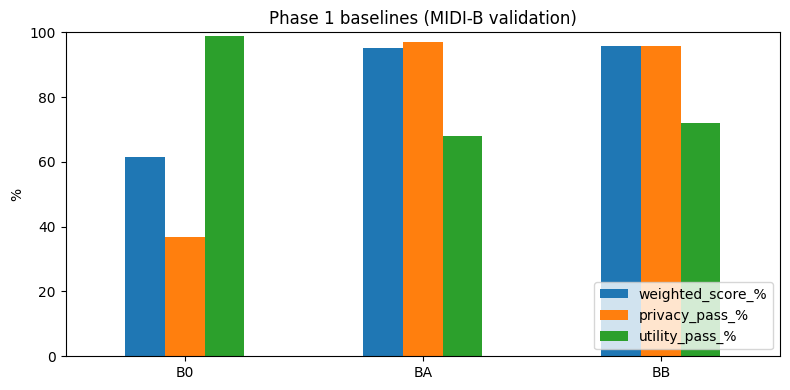

In [21]:
plot_table = baseline_table.loc[["weighted_score_%", "privacy_pass_%", "utility_pass_%"]].T
plot_table.plot(kind="bar", figsize=(8, 4), ylim=(0, 100))
plt.ylabel("%")
plt.title("Phase 1 baselines (MIDI-B validation)")
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.tight_layout()
plt.savefig(os.path.join(phase_results, "baseline_scores.png"), dpi=120)
plt.show()

## 6. Error analysis of the best baseline

In [22]:
best = baseline_table.loc["weighted_score_%"].astype(float).idxmax()
print("best baseline:", best)
failures = scoring.top_failures(all_results[best], n=25)
failures.to_csv(os.path.join(phase_results, "best_baseline_top_failures.csv"), index=False)
failures

best baseline: BB


,action,tag_name,failures
0,<text_retained>,<Private Creator>,79548
1,<text_retained>,<[PET compatible_version]>,34128
2,<text_retained>,<[PET software_version]>,28440
3,<text_retained>,<Study Description>,23661
4,<text_retained>,<Series Description>,23412
5,<text_removed>,<Series Number>,21268
6,<text_retained>,<Private tag data>,16628
7,<text_retained>,<[PET archived]>,11376
8,<text_retained>,<[PET axial_fov]>,8392
9,<text_retained>,<[PET bp_center_x]>,8392


In [23]:
# leaks (privacy failures) vs over-cleaning (utility failures), per tag
best_results = all_results[best]
failed = best_results[best_results["check_passed"].fillna(0).astype(float) < 1]
failed_privacy = failed[failed["action"].isin(scoring.PRIVACY_ACTIONS)]
failed_utility = failed[failed["action"].isin(scoring.UTILITY_ACTIONS)]
print("leaks (privacy failures):", len(failed_privacy))
print("over-cleaning (utility failures):", len(failed_utility))

print("\nTop leaking tags:")
print(failed_privacy["tag_name"].value_counts().head(15))
print("\nTop over-cleaned tags:")
print(failed_utility["tag_name"].value_counts().head(15))

leaks (privacy failures): 31131
over-cleaning (utility failures): 1458139

Top leaking tags:
tag_name
<Series Number>                        21268
<Retrieve AE Title>                     4140
<Device Serial Number>                  4061
<Performed Station AE Title>             787
<Station Name>                           776
<Mapping Resource UID>                    30
<Text Value>                              29
<Detector ID>                              5
<Coding Scheme UID>                        2
<Timezone Offset From UTC>                 2
<Scheduled Study Location AE Title>        1
<Gantry ID>                                1
Name: count, dtype: int64

Top over-cleaned tags:
tag_name
<Private Creator>             79548
<[PET compatible_version]>    34128
<[PET software_version]>      28440
<Study Description>           23661
<Series Description>          23412
<Private tag data>            16628
<[PET archived]>              11376
<[PET start_location]>         8392
<[PET deriv